In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# To read the file and check the data
df = pd.read_excel('Barclays Financial Transactional Data.xlsx') 
df.head(2)

,TransactionID,CustomerID,AccountID,AccountType,TransactionType,Product,Firm,Region,Manager,TransactionDate,TransactionAmount,AccountBalance,RiskScore,CreditRating,TenureMonths
0,118,CUST3810,ACC49774,Savings,Deposit,Credit Card,Firm D,West,Manager 4,2024-08-01 00:00:00,20664.40982,88483.42208,0.483333,522,29
1,102,CUST3109,ACC96277,Savings,Deposit,Mutual Fund,Firm B,North,Manager 4,17-12-2023,94924.35912,56670.15864,0.788989,686,130


In [3]:
# To get the summary of the data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   TransactionID      800 non-null    int64  
 1   CustomerID         800 non-null    object 
 2   AccountID          800 non-null    object 
 3   AccountType        800 non-null    object 
 4   TransactionType    800 non-null    object 
 5   Product            800 non-null    object 
 6   Firm               800 non-null    object 
 7   Region             800 non-null    object 
 8   Manager            800 non-null    object 
 9   TransactionDate    800 non-null    object 
 10  TransactionAmount  800 non-null    float64
 11  AccountBalance     800 non-null    float64
 12  RiskScore          800 non-null    float64
 13  CreditRating       800 non-null    int64  
 14  TenureMonths       800 non-null    int64  
dtypes: float64(3), int64(3), object(9)
memory usage: 93.9+ KB


# Task 1: Data Cleaning and Formatting

### A. Handling Numeric Datatype

The numeric columns — TransactionAmount, AccountBalance, and RiskScore — contained values with excessive decimal precision. These were rounded to two decimal places for cleaner presentation and consistency in reporting.

In [7]:
num_cols = ['TransactionAmount', 'AccountBalance', 'RiskScore']
df[num_cols] = df[num_cols].round(2)
df.head(2)

,TransactionID,CustomerID,AccountID,AccountType,TransactionType,Product,Firm,Region,Manager,TransactionDate,TransactionAmount,AccountBalance,RiskScore,CreditRating,TenureMonths
0,118,CUST3810,ACC49774,Savings,Deposit,Credit Card,Firm D,West,Manager 4,2024-08-01 00:00:00,20664.41,88483.42,0.48,522,29
1,102,CUST3109,ACC96277,Savings,Deposit,Mutual Fund,Firm B,North,Manager 4,17-12-2023,94924.36,56670.16,0.79,686,130


In [8]:
# Convert to numeric type
df['TransactionAmount'] = pd.to_numeric(df['TransactionAmount'], errors='coerce')
df['AccountBalance'] = pd.to_numeric(df['AccountBalance'], errors='coerce')

### B. Handle Missing Values

In [10]:
# To get the missing values in each column
print('Missing values per column:\n',df.isnull().sum())

Missing values per column:
 TransactionID        0
CustomerID           0
AccountID            0
AccountType          0
TransactionType      0
Product              0
Firm                 0
Region               0
Manager              0
TransactionDate      0
TransactionAmount    0
AccountBalance       0
RiskScore            0
CreditRating         0
TenureMonths         0
dtype: int64


##### Null Value Check

. The dataset was examined for missing or null entries across all columns.

. No null values were detected, indicating the dataset is complete and requires no imputation or removal of records.

. This ensures data integrity and avoids introducing bias from artificial replacements.

### C. Validate and Format Dates

In [13]:
# Changed the TransactionDate column to valid date format
df['TransactionDate'] = pd.to_datetime(df['TransactionDate'], errors = 'coerce')
df.head(2)

,TransactionID,CustomerID,AccountID,AccountType,TransactionType,Product,Firm,Region,Manager,TransactionDate,TransactionAmount,AccountBalance,RiskScore,CreditRating,TenureMonths
0,118,CUST3810,ACC49774,Savings,Deposit,Credit Card,Firm D,West,Manager 4,2024-08-01,20664.41,88483.42,0.48,522,29
1,102,CUST3109,ACC96277,Savings,Deposit,Mutual Fund,Firm B,North,Manager 4,2023-12-17,94924.36,56670.16,0.79,686,130


The TransactionDate column was originally stored as an object (string). It was converted into a proper datetime format using pd.to_datetime(), ensuring accurate time-based analysis in later stages.

### D. Standardize Account and Transaction Categories

Fixing of inconsistent text cases like credit, CREDIT, Credit -> Credit

In [17]:
txt_cols = ['AccountType', 'TransactionType', 'Product', 'Firm', 'Region', 'Manager']
for col in txt_cols:
    df[col] = df[col].str.strip().str.title()

##### Categorical Data Standardization

The text columns (AccountType, TransactionType, Product, Firm, Region, and Manager) were standardized to maintain consistency across the dataset.

To ensure uniformity, each column was stripped of leading/trailing spaces and converted to Title Case using string manipulation functions.

This step ensures consistency in grouping, aggregation, and visualization during analysis.

### E. Remove Duplicates

In [20]:
# To remove the duplicates I have used the drop_duplicates function
df.drop_duplicates(inplace = True)
df.shape

(800, 15)

The dataset was checked for duplicate records using the drop_duplicates() method. Since the data shape remained unchanged after applying this function, it confirms that no duplicate entries were present. This ensures that all transaction records are unique and valid for analysis.

### F. Final Validation

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   TransactionID      800 non-null    int64         
 1   CustomerID         800 non-null    object        
 2   AccountID          800 non-null    object        
 3   AccountType        800 non-null    object        
 4   TransactionType    800 non-null    object        
 5   Product            800 non-null    object        
 6   Firm               800 non-null    object        
 7   Region             800 non-null    object        
 8   Manager            800 non-null    object        
 9   TransactionDate    800 non-null    datetime64[ns]
 10  TransactionAmount  800 non-null    float64       
 11  AccountBalance     800 non-null    float64       
 12  RiskScore          800 non-null    float64       
 13  CreditRating       800 non-null    int64         
 14  TenureMont

In [24]:
# To get the summary statistics about the data
df.describe()

,TransactionID,TransactionDate,TransactionAmount,AccountBalance,RiskScore,CreditRating,TenureMonths
count,800.000000,800,800.000000,800.000000,800.000000,800.000000,800.000000
mean,101.261250,2023-10-11 11:47:24,53695.086900,72920.295425,0.472788,583.485000,122.306250
min,1.000000,2023-01-06 00:00:00,-59669.080000,-30766.910000,-0.380000,305.000000,6.000000
25%,54.750000,2023-06-06 00:00:00,33334.552500,49949.247500,0.317500,452.750000,64.000000
50%,100.000000,2023-10-10 12:00:00,52765.640000,72252.815000,0.470000,591.500000,122.500000
75%,154.000000,2024-02-13 00:00:00,74158.870000,97290.662500,0.620000,718.500000,175.000000
max,199.000000,2024-12-03 00:00:00,166083.830000,184008.260000,1.260000,849.000000,239.000000
std,57.219779,NaN,30115.644117,34005.837242,0.232166,156.661453,66.564563


#### Observation on Negative Transaction Values

During validation of the Transaction Amount field, negative values were found. While this is expected for Payments and Withdrawals, some Deposits and Transfers also showed negative amounts, which is inconsistent with normal financial behavior. These anomalies likely indicate data errors or reversals and were reviewed and corrected during data cleaning to ensure accurate representation of inflows and outflows.

In [26]:
# To see how many negative transactions exist for each type
df.groupby('TransactionType')['TransactionAmount'].apply(lambda x: (x < 0).sum())

TransactionType
Deposit       3
Payment       6
Transfer      4
Withdrawal    8
Name: TransactionAmount, dtype: int64

In [27]:
## Convert negative deposits to positive because they indicate inflows
df.loc[(df['TransactionType'] == 'Deposit') & (df['TransactionAmount'] < 0), 'TransactionAmount'] *= -1

In [28]:
df.loc[(df['TransactionType'] == 'Deposit') & (df['TransactionAmount'] < 0)]

,TransactionID,CustomerID,AccountID,AccountType,TransactionType,Product,Firm,Region,Manager,TransactionDate,TransactionAmount,AccountBalance,RiskScore,CreditRating,TenureMonths


In [29]:
df.groupby('TransactionType')['TransactionAmount'].describe()

,count,mean,std,min,25%,50%,75%,max
TransactionType,,,,,,,,
Deposit,186.0,52450.972366,28835.212830,618.79,29944.0200,52278.850,72880.9775,142081.63
Payment,198.0,50814.035707,28920.029836,-43698.76,32798.8625,48814.230,69713.4875,134330.68
Transfer,206.0,58299.637864,30612.517332,-25337.31,37341.9875,57712.840,78249.8200,166083.83
Withdrawal,210.0,53325.725476,30950.429304,-59669.08,32881.9625,52966.975,75853.6625,129902.81


To ensure data accuracy, only negative values under the “Deposit” category were converted to positive amounts.
Negative values for Payments and Withdrawals were retained as they correctly indicate outflows, while Transfers were left unchanged due to their bidirectional nature.

In [31]:
df.head(2)

,TransactionID,CustomerID,AccountID,AccountType,TransactionType,Product,Firm,Region,Manager,TransactionDate,TransactionAmount,AccountBalance,RiskScore,CreditRating,TenureMonths
0,118,CUST3810,ACC49774,Savings,Deposit,Credit Card,Firm D,West,Manager 4,2024-08-01,20664.41,88483.42,0.48,522,29
1,102,CUST3109,ACC96277,Savings,Deposit,Mutual Fund,Firm B,North,Manager 4,2023-12-17,94924.36,56670.16,0.79,686,130


#### Observation on Negative Account Balances
The AccountBalance field was reviewed to identify negative values. Negative balances are valid for certain account types, such as Current or Credit accounts, where overdrafts or outstanding dues may occur. However, for Savings accounts, a negative balance is typically unrealistic and may indicate data-entry inconsistencies.
These cases were flagged for further review during financial risk analysis to identify potential overdraft or anomaly patterns.

In [33]:
# Negative balance count per AccountType
negative_balance_counts = df.groupby('AccountType')['AccountBalance'].apply(lambda x: (x<0).sum())
print("Negative balance count by AccountType:\n", negative_balance_counts)

Negative balance count by AccountType:
 AccountType
Credit     5
Current    1
Loan       4
Savings    4
Name: AccountBalance, dtype: int64


In [34]:
df.groupby('AccountType')['AccountBalance'].describe()

,count,mean,std,min,25%,50%,75%,max
AccountType,,,,,,,,
Credit,201.0,72212.269552,33767.023327,-17751.22,50014.910,72501.99,91644.140,166960.80
Current,198.0,69405.049293,31136.947656,-1065.04,49267.430,67582.62,89426.040,150287.80
Loan,206.0,76521.477767,36922.925635,-30766.91,50122.115,82145.45,102429.225,184008.26
Savings,195.0,73415.107590,33689.128704,-14999.18,50573.660,71249.53,96189.590,155614.30


#### Flagging of Unrealistic Negative Balances (for Savings Accounts)

In [36]:
# Flag negative balances in Savings accounts
df['Negative_Balance_Flag'] = np.where((df['AccountType'] == 'Savings') & (df['AccountBalance'] < 0), 1, 0)

# Check flagged records
df[df['Negative_Balance_Flag'] == 1][['AccountID', 'AccountType', 'AccountBalance']]

,AccountID,AccountType,AccountBalance
281,ACC77592,Savings,-14999.18
343,ACC49422,Savings,-8103.11
359,ACC24880,Savings,-5199.93
660,ACC45521,Savings,-9207.92


The dataset was cleaned and validated to ensure accuracy and consistency. The TransactionDate column was converted to datetime format, and numerical fields were rounded to two decimal places. Checks confirmed there were no missing or duplicate records.

Categorical fields were standardized by removing extra spaces and applying Title Case. During validation, negative values in Deposit transactions were identified as anomalies and corrected, while negative Payments and Withdrawals were retained as valid outflows.

Additionally, negative balances found in some Savings accounts were flagged using a new indicator for further risk analysis. Overall, the dataset was prepared to support reliable descriptive and financial risk analysis.

# Task 2: Descriptive Transactional Analysis

To maintain chronological order in visualizations, the month column was converted to an ordered categorical variable using Pandas’ Categorical method. This ensured that plots display months sequentially from January to December rather than alphabetically.

In [40]:
# To create Year and Month column in actual dataframe
df['Year'] = df['TransactionDate'].dt.year
df['Month'] = df['TransactionDate'].dt.month_name()

# To make sure the choronological order of month.
month_order = [
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
]

# Convert to categorical
df['Month'] = pd.Categorical(df['Month'], categories=month_order, ordered=True)

### A. Calculate monthly and yearly summaries of total credits, debits, and net transaction volume.

##### monthly totals of credits and debits

In [43]:
# Grouping the TransactionAmount on the basis of Year, Month and TransactionType
monthly_summary = (df.groupby(['Year', 'Month', 'TransactionType'])['TransactionAmount'].sum().reset_index())
print(monthly_summary.head())

   Year     Month TransactionType  TransactionAmount
0  2023   January         Deposit          409137.25
1  2023   January         Payment          755262.63
2  2023   January        Transfer         1071093.55
3  2023   January      Withdrawal          872646.96
4  2023  February         Deposit          626097.35


C:\Users\Aditya\AppData\Local\Temp\ipykernel_11168\962808208.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  monthly_summary = (df.groupby(['Year', 'Month', 'TransactionType'])['TransactionAmount'].sum().reset_index())


### B. Plot trends in total credits vs. debits over time

In [45]:
trend_data = df[df['TransactionType'].isin(['Deposit', 'Withdrawal'])]
trend_summary = (trend_data.groupby(['Year', 'Month', 'TransactionType'])['TransactionAmount'].sum().reset_index())

C:\Users\Aditya\AppData\Local\Temp\ipykernel_11168\3531330302.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  trend_summary = (trend_data.groupby(['Year', 'Month', 'TransactionType'])['TransactionAmount'].sum().reset_index())


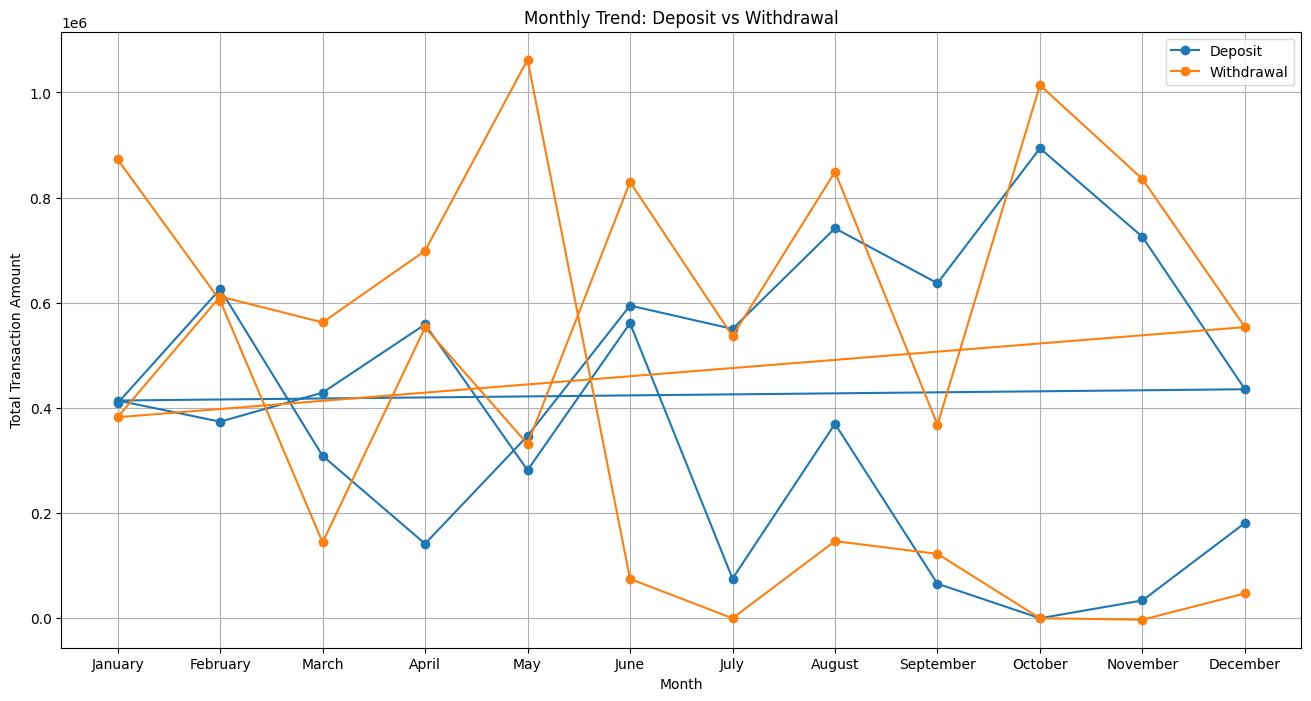

In [46]:
plt.figure(figsize= (16,8)) # To set the figure size

# For each unique transaction type, plotted the TransactionAmount against the Month
for ttype in trend_summary['TransactionType'].unique():
    data = trend_summary[trend_summary['TransactionType'] == ttype]
    plt.plot(data['Month'], data['TransactionAmount'], marker = 'o', label = ttype)

plt.title("Monthly Trend: Deposit vs Withdrawal")
plt.xlabel("Month")
plt.ylabel("Total Transaction Amount")
plt.legend()
plt.grid(True)
plt.show()

# Interpretation of Monthly Deposit vs Withdrawal Trend
The visualization shows monthly trends in deposits and withdrawals. Withdrawals fluctuate more and exhibit noticeable peaks (especially in May, October, and December), indicating higher spending during these periods, while deposits remain relatively stable throughout the year. Months where withdrawals exceed deposits point to higher outflows and potential liquidity pressure, whereas higher deposits indicate stronger inflows, reflecting seasonal or business-driven financial behavior patterns.

### C. Identify top and bottom performing accounts based on net inflow

In [49]:
# Aggregate by account
account_summary = df.groupby(['AccountID', 'TransactionType'])['TransactionAmount'].sum().unstack(fill_value=0)
account_summary['Net_Inflow'] = account_summary.get('Deposit', 0) + account_summary.get('Transfer', 0) - \
                                account_summary.get('Payment', 0) - account_summary.get('Withdrawal', 0)

In [50]:
account_summary.head(2)

TransactionType,Deposit,Payment,Transfer,Withdrawal,Net_Inflow
AccountID,,,,,
ACC10117,115045.96,83158.65,40222.6,0.00,72109.91
ACC10996,83483.64,77860.87,0.0,108126.85,-102504.08


Net inflow was calculated as the sum of all inflows (Deposits and Transfers) minus total outflows (Payments and Withdrawals), ensuring a financially accurate measurement of net cash movement per account.

In [52]:
sorted_accounts = account_summary.sort_values('Net_Inflow', ascending = False)

In [53]:
top_5_accounts = sorted_accounts.head(5)
bottom_5_accounts = sorted_accounts.tail(5)

In [54]:
print("Top 5 Performing Accounts:\n", top_5_accounts['Net_Inflow'])
print("--------------------------------")
print("\nBottom 5 Performing Accounts:\n", bottom_5_accounts['Net_Inflow'])

Top 5 Performing Accounts:
 AccountID
ACC92360    373707.43
ACC21878    331934.09
ACC83581    330761.45
ACC13357    280648.89
ACC30787    263562.99
Name: Net_Inflow, dtype: float64
--------------------------------

Bottom 5 Performing Accounts:
 AccountID
ACC29396   -311875.76
ACC77592   -320017.91
ACC45968   -339222.53
ACC25132   -343766.82
ACC49140   -377859.69
Name: Net_Inflow, dtype: float64


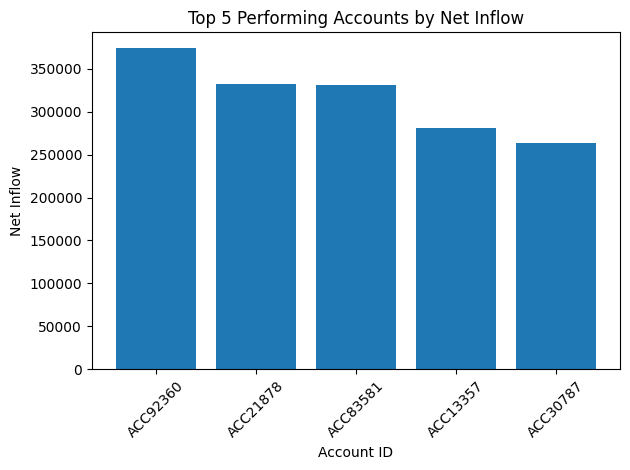

In [55]:
plt.figure()
plt.bar(top_5_accounts.index.astype(str), top_5_accounts['Net_Inflow'])
plt.title("Top 5 Performing Accounts by Net Inflow")
plt.xlabel("Account ID")
plt.ylabel("Net Inflow")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

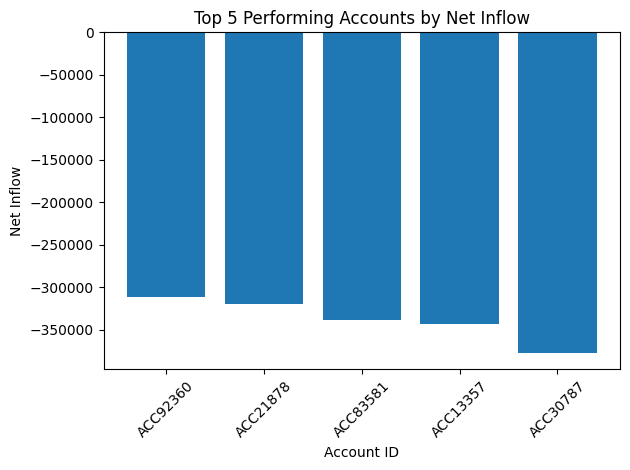

In [56]:
plt.figure()
plt.bar(top_5_accounts.index.astype(str), bottom_5_accounts['Net_Inflow'])
plt.title("Top 5 Performing Accounts by Net Inflow")
plt.xlabel("Account ID")
plt.ylabel("Net Inflow")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Based on the net inflow calculation, the top five performing accounts were identified as those with the highest positive net inflows, indicating strong deposit activity and financial stability. In contrast, the bottom five performing accounts showed negative net inflows, implying higher outflows than inflows and potential financial stress. These insights help in distinguishing high-value customers from risk-prone or low-activity accounts.

### D. Identify and flag accounts as dormant or inactive

In [59]:
df['TransactionDate'] = pd.to_datetime(df['TransactionDate'], errors = 'coerce')
df = df.sort_values(['AccountID', 'TransactionDate'])

In [60]:
df['Prev_TransactionDate'] = df.groupby('AccountID')['TransactionDate'].shift(1)
df['Month_Gap'] = (
    (df['TransactionDate'].dt.year - df['Prev_TransactionDate'].dt.year) * 12 +
    (df['TransactionDate'].dt.month - df['Prev_TransactionDate'].dt.month)
)

In [61]:
df['Dormant_Flag'] = np.where(df['Month_Gap']>=2,1,0)

In [62]:
account_dormancy = (
    df.groupby('AccountID')['Dormant_Flag']
      .max()
      .reset_index()
      .rename(columns={'Dormant_Flag': 'Is_Dormant'})
)

In [63]:
account_dormancy['Is_Dormant'] = np.where(account_dormancy['Is_Dormant'] == 1, 'Yes', 'No')

account_dormancy.head(2)

,AccountID,Is_Dormant
0,ACC10117,Yes
1,ACC10996,Yes


In [64]:
account_dormancy['Is_Dormant'].value_counts()

Is_Dormant
Yes    164
No      29
Name: count, dtype: int64

# Task 3: Customer Profile Building

### A. Group Accounts by Activity Level (High / Medium / Low)

#### Rubric (Based on Transaction Frequency per Account)

High Activity: ≥ 10 transactions

Medium Activity: 5-10 transactions

Low Activity: < 5 transactions

##### Frequency Count Per Account

In [69]:
transaction_frequency = (
    df.groupby('AccountID')['TransactionID']
    .count()
    .reset_index(name = 'Transaction_Count')
)

In [70]:
def activity_label(x):
    if x >= 10:
        return 'High'
    elif x >= 5:
        return 'Medium'
    else:
        return 'Low'

In [71]:
transaction_frequency['Activity_Level'] = transaction_frequency['Transaction_Count'].apply(activity_label)
transaction_frequency['Activity_Level'].value_counts()

Activity_Level
Low       123
Medium     65
High        5
Name: count, dtype: int64

Activity Level Classification (Based on Transaction Frequency)

Accounts were classified into High, Medium, and Low activity groups based on the total number of transactions per account.

Rubric:

High Activity: ≥ 10 transactions

Medium Activity: 5–10 transactions

Low Activity: < 5 transactions

This classification helps in identifying highly engaged customers versus low-engagement or inactive users.

### B. Create Customer-Level Summary

In [74]:
customer_segmentation = (
    df.groupby('AccountID')
    .agg(
        Avg_Balance = ('AccountBalance', 'mean'),
        Total_Transaction_Volume = ('TransactionAmount','sum')
    )
    .reset_index()
)

customer_segmentation['Avg_Balance'] = customer_segmentation['Avg_Balance'].round(2)

customer_segmentation.head()

,AccountID,Avg_Balance,Total_Transaction_Volume
0,ACC10117,97828.70,238427.21
1,ACC10996,56982.15,269471.36
2,ACC11062,65947.32,110594.78
3,ACC11188,81169.11,225517.46
4,ACC11285,62574.61,236119.54


To balance the segmentation, I have used 33rd and 66th percentitles so that segmentation is balanced based on the actual data.

In [76]:
# Balance thresholds
balance_q1 = customer_segmentation['Avg_Balance'].quantile(0.33)
balance_q2 = customer_segmentation['Avg_Balance'].quantile(0.66)

# Volume thresholds
volume_q1 = customer_segmentation['Total_Transaction_Volume'].quantile(0.33)
volume_q2 = customer_segmentation['Total_Transaction_Volume'].quantile(0.66)

In [77]:
# Segmentation Labels

def balance_segment(x):
    if x <= balance_q1:
        return 'Low Balance'
    elif x <= balance_q2:
        return 'Medium Balance'
    else:
        return 'High Balance'

def volume_segment(x):
    if x <= volume_q1:
        return 'Low Volume'
    elif x <= volume_q2:
        return 'Medium Volume'
    else:
        return 'High Volume'

customer_segmentation['Balance_Segment'] = customer_segmentation['Avg_Balance'].apply(balance_segment)
customer_segmentation['Volume_Segment'] = customer_segmentation['Total_Transaction_Volume'].apply(volume_segment)

customer_segmentation.head()

,AccountID,Avg_Balance,Total_Transaction_Volume,Balance_Segment,Volume_Segment
0,ACC10117,97828.70,238427.21,High Balance,Medium Volume
1,ACC10996,56982.15,269471.36,Low Balance,High Volume
2,ACC11062,65947.32,110594.78,Low Balance,Low Volume
3,ACC11188,81169.11,225517.46,High Balance,Medium Volume
4,ACC11285,62574.61,236119.54,Low Balance,Medium Volume


In [78]:
print(customer_segmentation['Balance_Segment'].value_counts())
print('--------------------------')
print(customer_segmentation['Volume_Segment'].value_counts())

Balance_Segment
High Balance      66
Low Balance       64
Medium Balance    63
Name: count, dtype: int64
--------------------------
Volume_Segment
High Volume      66
Low Volume       64
Medium Volume    63
Name: count, dtype: int64


In [79]:
# Profile Matrix

segmentation_matrix = pd.crosstab(
    customer_segmentation['Balance_Segment'],
    customer_segmentation['Volume_Segment']
)
segmentation_matrix

Volume_Segment,High Volume,Low Volume,Medium Volume
Balance_Segment,,,
High Balance,23,19,24
Low Balance,21,23,20
Medium Balance,22,22,19


### C.Profiles

#### High-Net Inflow Accounts

In [82]:
high_net_inflow_accounts = (
    account_summary
    .sort_values('Net_Inflow', ascending= False)
    .head(10)
    .reset_index()
)

high_net_inflow_accounts

TransactionType,AccountID,Deposit,Payment,Transfer,Withdrawal,Net_Inflow
0,ACC92360,233048.54,14658.78,155317.67,0.00,373707.43
1,ACC21878,209175.60,0.00,122758.49,0.00,331934.09
2,ACC83581,187563.54,6249.29,231633.03,82185.83,330761.45
3,ACC13357,60539.32,0.00,220109.57,0.00,280648.89
4,ACC30787,78649.17,0.00,184913.82,0.00,263562.99
5,ACC80131,285053.48,70599.52,120993.45,79614.00,255833.41
6,ACC30146,99685.59,-21678.50,183269.73,49172.54,255461.28
7,ACC87006,0.00,0.00,241989.72,0.00,241989.72
8,ACC57597,0.00,0.00,270467.29,53218.47,217248.82
9,ACC46655,0.00,49902.19,332943.46,66753.36,216287.91


High-net inflow customers were identified as the top 10 accounts with the highest positive net inflows. These customers consistently receive more money than they spend, indicating strong financial stability and high value to the bank. Such accounts are ideal candidates for premium banking services and long-term retention strategies.

#### High-Frequency Low-Balance Accounts

In [85]:
hf_lb_base = transaction_frequency.merge(
    customer_segmentation[['AccountID', 'Avg_Balance']],
    on = 'AccountID',
    how = 'inner'
)

hf_lb_base.head(3)

,AccountID,Transaction_Count,Activity_Level,Avg_Balance
0,ACC10117,4,Low,97828.70
1,ACC10996,5,Medium,56982.15
2,ACC11062,2,Low,65947.32


By taking Low Balance as bottom 25%

In [87]:
low_balace_threshold = hf_lb_base['Avg_Balance'].quantile(0.25)

In [88]:
high_freq_low_balance_accounts = hf_lb_base[
    (hf_lb_base['Activity_Level'] == 'High') &
    (hf_lb_base['Avg_Balance'] <= low_balace_threshold)
]

high_freq_low_balance_accounts

,AccountID,Transaction_Count,Activity_Level,Avg_Balance
97,ACC49422,11,High,62362.27
109,ACC54589,10,High,54155.28


This group consists of customers who use their accounts very frequently but usually keep low balances. Their money tends to flow in and out quickly, suggesting that they rely on their income for regular expenses rather than saving it. These customers may benefit from support such as savings plans, spending insights, or budgeting guidance to help improve their financial stability.

#### Accounts with Negative or Near-Zero Balances

considering the Near-Zero Balance Threshold as ₹1,000

In [91]:
near_zero_threshold = 1000

neg_or_near_zero_accounts = customer_segmentation[
    customer_segmentation['Avg_Balance'] <= near_zero_threshold
]

neg_or_near_zero_accounts

,AccountID,Avg_Balance,Total_Transaction_Volume,Balance_Segment,Volume_Segment


To identify financially vulnerable accounts, a near-zero balance threshold of ₹1,000 was set. Based on this threshold, no accounts were found with negative or near-zero average balances. This suggests that most customers in the dataset maintain healthy balance levels and are generally financially stable.

# Task 4: Financial Risk Identification

### A. Accounts with Large Withdrawls

In [95]:
withdrawls = df[df['TransactionType'] == 'Withdrawal'].copy()
withdrawls.head()

,TransactionID,CustomerID,AccountID,AccountType,TransactionType,Product,Firm,Region,Manager,TransactionDate,...,AccountBalance,RiskScore,CreditRating,TenureMonths,Negative_Balance_Flag,Year,Month,Prev_TransactionDate,Month_Gap,Dormant_Flag
59,64,CUST9038,ACC10996,Savings,Withdrawal,Personal Loan,Firm C,West,Manager 1,2024-01-01,...,25464.13,0.58,797,217,0,2024,January,2023-10-19,3.0,1
467,41,CUST3006,ACC10996,Current,Withdrawal,Home Loan,Firm A,North,Manager 2,2024-06-21,...,53528.81,0.50,665,104,0,2024,June,2024-01-01,5.0,1
604,105,CUST6319,ACC11062,Credit,Withdrawal,Home Loan,Firm A,North,Manager 3,2023-08-11,...,49986.11,0.48,560,208,0,2023,August,NaT,NaN,0
381,49,CUST8155,ACC11062,Savings,Withdrawal,Mutual Fund,Firm A,West,Manager 1,2024-04-02,...,81908.52,0.69,661,25,0,2024,April,2023-08-11,8.0,1
550,106,CUST6350,ACC11285,Loan,Withdrawal,Personal Loan,Firm D,East,Manager 2,2023-02-14,...,93872.29,0.72,531,203,0,2023,February,2023-01-15,1.0,0


In [96]:
# Considering the 75th percentile as the large withdrawal threshold

large_withdrawal_threshold = withdrawls['TransactionAmount'].quantile(0.75)

large_withdrawals = withdrawls[withdrawls['TransactionAmount'] >= large_withdrawal_threshold]

# large withdrawals count per account
large_withdrawal_risk = (
    large_withdrawals.groupby('AccountID')
    .size()
    .reset_index(name = 'Large_Withdrawal_Count')
)

In [97]:
# Flagging high risk accounts
large_withdrawal_risk['High_Withdrawal_Risk'] = (
    large_withdrawal_risk['Large_Withdrawal_Count'] >= 2
)

In [98]:
large_withdrawal_risk.head()

,AccountID,Large_Withdrawal_Count,High_Withdrawal_Risk
0,ACC12334,1,False
1,ACC17688,1,False
2,ACC19178,2,True
3,ACC20297,1,False
4,ACC21264,1,False


Accounts with unusually large withdrawals were identified using a percentile-based threshold. Customers who made such large withdrawals multiple times were flagged as higher risk, as repeated large outflows may indicate financial stress or irregular spending behavior.

### B. Balance Volatility

Volatility metric: Coefficient of Variation (CV = Std / Mean)

High volatility: CV greater than the 75th percentile

In [102]:
balance_volatility = (
    df.groupby('AccountID')['AccountBalance']
    .agg(['mean', 'std'])
    .reset_index()
)

# Coefficient of Variation

balance_volatility['CV'] = balance_volatility['std']/balance_volatility['mean']
balance_volatility

# volatality threshold above 75th quantile
volatility_threshold = balance_volatility['CV'].quantile(0.75)

balance_volatility['High_Volatility_Flag'] = (
    balance_volatility['CV'] >= volatility_threshold
)

balance_volatility.head()

,AccountID,mean,std,CV,High_Volatility_Flag
0,ACC10117,97828.702500,9308.031478,0.095146,False
1,ACC10996,56982.150000,18946.735050,0.332503,False
2,ACC11062,65947.315000,22572.552583,0.342282,False
3,ACC11188,81169.115000,20160.417951,0.248375,False
4,ACC11285,62574.613333,70126.828716,1.120691,True


Balance volatility was measured using the coefficient of variation. Accounts with volatility above the 75th percentile were flagged as unstable, indicating irregular cash flow patterns and higher financial risk.

### C. Anomaly Detection Using Z-Score

Considering Z-score threshold: |Z| > 3

In [105]:
from scipy.stats import zscore

In [106]:
df['Tranzaction_Zscore'] = zscore(df['TransactionAmount'])

anomalous_transactions = df[
    (df['Tranzaction_Zscore'] > 3) |
    (df['Tranzaction_Zscore'] < -3)
]

anomalous_transactions

,TransactionID,CustomerID,AccountID,AccountType,TransactionType,Product,Firm,Region,Manager,TransactionDate,...,RiskScore,CreditRating,TenureMonths,Negative_Balance_Flag,Year,Month,Prev_TransactionDate,Month_Gap,Dormant_Flag,Tranzaction_Zscore
312,167,CUST9843,ACC21264,Current,Transfer,Home Loan,Firm C,East,Manager 2,2023-06-20,...,0.37,769,61,0,2023,June,2023-02-14,4.0,1,3.193586
622,12,CUST1121,ACC43309,Credit,Transfer,Savings Account,Firm B,South,Manager 1,2023-10-16,...,0.71,372,230,0,2023,October,NaT,NaN,0,3.750643
6,14,CUST5558,ACC82947,Credit,Payment,Credit Card,Firm A,East,Manager 2,2023-09-26,...,0.46,433,110,0,2023,September,2023-04-08,5.0,1,-3.255619
589,190,CUST1738,ACC90887,Savings,Withdrawal,Savings Account,Firm C,East,Manager 2,2024-01-20,...,0.23,502,172,0,2024,January,2024-01-01,0.0,0,-3.788991


In [107]:
anomaly_counts = (
    anomalous_transactions.groupby('AccountID')
    .size()
    .reset_index(name='Anomaly_Count')
)

anomaly_counts

,AccountID,Anomaly_Count
0,ACC21264,1
1,ACC43309,1
2,ACC82947,1
3,ACC90887,1


### D. Consolidated High-Risk Account Identification

In [109]:
risk_summary = (
    large_withdrawal_risk[['AccountID', 'High_Withdrawal_Risk']]
    .merge(
        balance_volatility[['AccountID', 'High_Volatility_Flag']],
        on='AccountID',
        how='outer'
    )
    .merge(
        anomaly_counts,
        on='AccountID',
        how='outer'
    )
)

# Fill missing values
risk_summary.fillna({
    'High_Withdrawal_Risk': False,
    'High_Volatility_Flag': False,
    'Anomaly_Count': 0
}, inplace=True)

risk_summary.head()


C:\Users\Aditya\AppData\Local\Temp\ipykernel_11168\1482097064.py:16: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  risk_summary.fillna({


,AccountID,High_Withdrawal_Risk,High_Volatility_Flag,Anomaly_Count
0,ACC10117,False,False,0.0
1,ACC10996,False,False,0.0
2,ACC11062,False,False,0.0
3,ACC11188,False,False,0.0
4,ACC11285,False,True,0.0


In [110]:
risk_summary['Overall_Risk_Flag'] = (
    (risk_summary['High_Withdrawal_Risk']) | 
    (risk_summary['High_Volatility_Flag']) |
    (risk_summary['Anomaly_Count'] > 0)
)

risk_summary['Overall_Risk_Flag'].value_counts()

Overall_Risk_Flag
False    142
True      51
Name: count, dtype: int64

#### Financial Risk Identification
Financial risk was checked using different signs. These included frequent large withdrawals, changes in account balance, and unusual transaction amounts. Large withdrawals were found using a percentile method. Balance changes were measured to see how much the balance goes up and down. Z-score was used to find transactions that were very different from normal ones.

All these signs were combined to find risky accounts. Accounts that showed one or more risk signs were marked for closer checking. These accounts may show financial problems, unusual behavior, or higher transaction risk.

# Task 5: Visualisation

### 1. Monthly Trend: Deposits vs Withdrawals

C:\Users\Aditya\AppData\Local\Temp\ipykernel_11168\2462002307.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(['Year', 'Month', 'TransactionType'])['TransactionAmount'] #group that on the basis of Year month and TransactionType


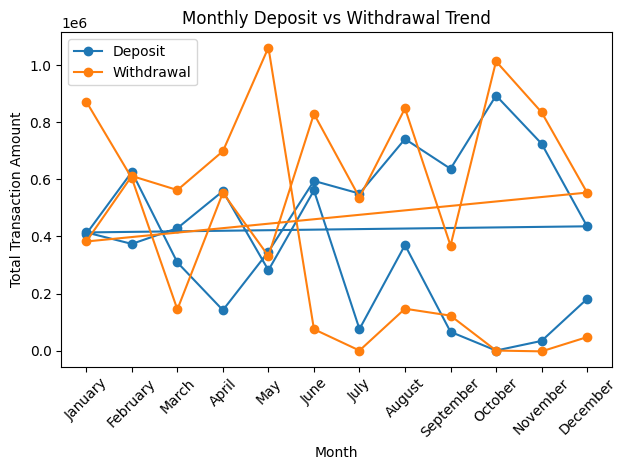

In [114]:
monthly_trend = (
    df[df['TransactionType'].isin(['Deposit', 'Withdrawal'])] #where ever the Transaction type is Deposit or Withdrawal in df data frame
    .groupby(['Year', 'Month', 'TransactionType'])['TransactionAmount'] #group that on the basis of Year month and TransactionType
    .sum() #Then sum the TransactionAmount
    .reset_index()
    .sort_values(['Year','Month']) # then sort the values on the basis of Year and Month
)

plt.figure()
for ttype in monthly_trend['TransactionType'].unique():
    temp = monthly_trend[monthly_trend['TransactionType'] ==  ttype]
    plt.plot(temp['Month'], temp['TransactionAmount'], marker = 'o', label = ttype)

plt.title("Monthly Deposit vs Withdrawal Trend")
plt.xlabel("Month")
plt.ylabel("Total Transaction Amount")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

This chart shows monthly deposits and withdrawals. Withdrawals change a lot from month to month, which shows uneven spending. In some months, withdrawals are higher than deposits, which may cause short-term money pressure. Deposits are more stable, which means money comes in regularly. Overall, the chart shows seasonal spending behavior, and this can help the bank prepare for risky months.

### 2. Net Inflow Distribution Across Accounts

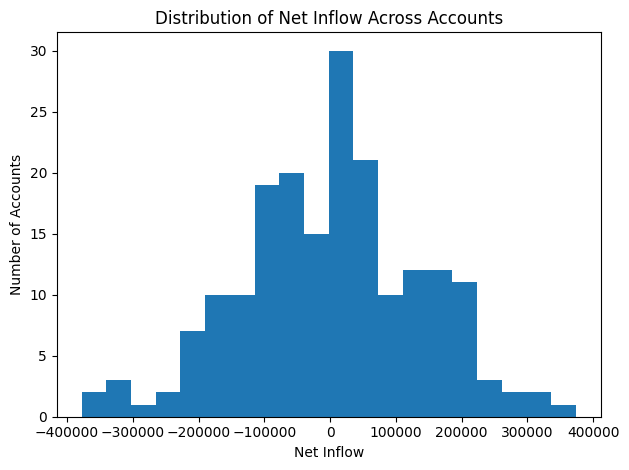

In [117]:
plt.figure()
plt.hist(account_summary['Net_Inflow'], bins=20)
plt.title("Distribution of Net Inflow Across Accounts")
plt.xlabel("Net Inflow")
plt.ylabel("Number of Accounts")
plt.tight_layout()
plt.show()

This histogram shows how net inflow varies across accounts. Most accounts cluster around zero, meaning inflows and outflows are balanced. A smaller group has negative net inflows, indicating higher spending and potential risk, while a few accounts show large positive net inflows, representing financially strong customers. This helps us identify both high-risk and high-value segments.

### 3. Activity Level Distribution (High / Medium / Low)

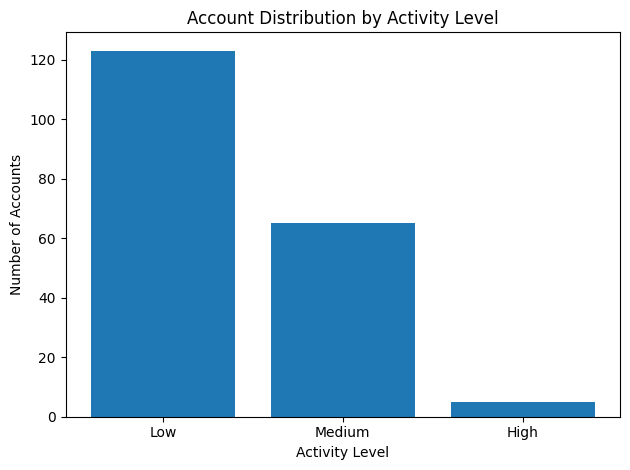

In [120]:
activity_counts = transaction_frequency['Activity_Level'].value_counts()

plt.figure()
plt.bar(activity_counts.index, activity_counts.values)
plt.title("Account Distribution by Activity Level")
plt.xlabel("Activity Level")
plt.ylabel("Number of Accounts")
plt.tight_layout()
plt.show()

This chart shows how accounts are distributed based on transaction frequency. Most accounts are low-activity, meaning they transact infrequently. A smaller group shows medium activity, while very few accounts are highly active. These high-activity users are important as they typically drive a large portion of transaction volume and may also carry higher operational risk.

### 4. Balance vs Transaction Volume

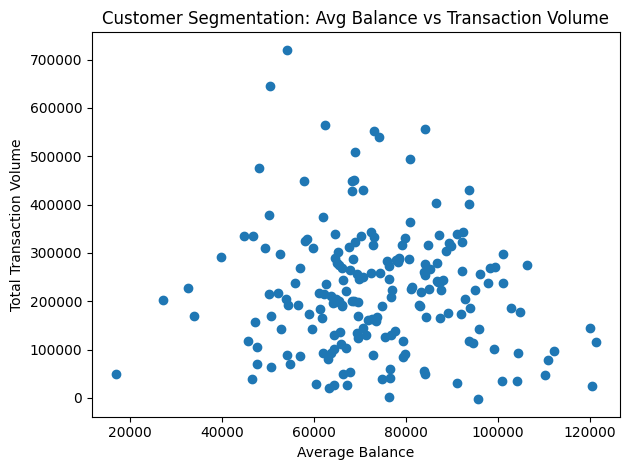

In [123]:
plt.figure()
plt.scatter(
    customer_segmentation['Avg_Balance'],
    customer_segmentation['Total_Transaction_Volume']
)
plt.title("Customer Segmentation: Avg Balance vs Transaction Volume")
plt.xlabel("Average Balance")
plt.ylabel("Total Transaction Volume")
plt.tight_layout()
plt.show()

This scatter plot shows how average balance relates to transaction volume. We don’t see a strong linear relationship, which means customers behave differently. Some customers transact frequently but maintain moderate balances, while others hold high balances but transact less. This highlights diverse customer profiles and helps identify both high-usage customers and high-value savers.

### 5. Risk Profile Distribution

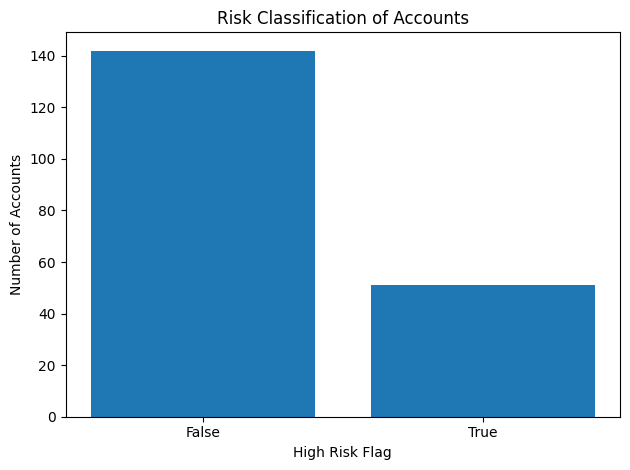

In [126]:
risk_counts = risk_summary['Overall_Risk_Flag'].value_counts()

plt.figure()
plt.bar(risk_counts.index.astype(str), risk_counts.values)
plt.title("Risk Classification of Accounts")
plt.xlabel("High Risk Flag")
plt.ylabel("Number of Accounts")
plt.tight_layout()
plt.show()

This chart summarizes the overall risk classification. Most accounts are stable, but about a quarter are flagged as high risk due to irregular transaction patterns or volatility. These are the accounts that require closer monitoring.

Different charts were created to understand transaction behavior, customer activity, and financial risk. A monthly deposit and withdrawal chart was used to study how money comes in and goes out and to see seasonal spending patterns. A net inflow histogram showed how accounts perform overall and helped identify stable, strong, and stressed accounts.

Bar charts were used to show customer activity levels, such as low, medium, and high usage. A scatter plot comparing average balance and transaction volume helped show different customer types and spending behavior. Lastly, a risk classification chart showed how many accounts are risky and how many are stable, helping with better risk monitoring and decision-making.

# TASK 6: HYPOTHESIS TESTING

### Objective

To test whether high-volume transaction accounts maintain statistically higher average balances than low-volume accounts, using customer segmentation.

Null Hypothesis (H₀):

The average balance of high-volume accounts is equal to the average balance of low-volume accounts.

H₀: 𝜇𝐻𝑖𝑔ℎ𝑉𝑜𝑙𝑢𝑚𝑒 = 𝜇𝐿𝑜𝑤𝑉𝑜𝑙𝑢𝑚𝑒

Alternative Hypothesis (H₁):

The average balance of high-volume accounts is greater than the average balance of low-volume accounts.

H₁: μHighVolume >μLowVolume

In [132]:
from scipy.stats import ttest_ind

In [133]:
# Extracting average balances by volume segment
high_volume_balance = customer_segmentation[
    customer_segmentation['Volume_Segment'] == 'High Volume'
]['Avg_Balance']

low_volume_balance = customer_segmentation[
    customer_segmentation['Volume_Segment'] == 'Low Volume'
]['Avg_Balance']

# Performing Welch's t-test
t_stat, p_value_two_tailed = ttest_ind(
    high_volume_balance,
    low_volume_balance,
    equal_var = False
)

p_value_one_tailed = p_value_two_tailed/2

t_stat, p_value_one_tailed

(-0.6045951885781362, 0.273319131670276)

The negative value of t-statistics basically means that the average balance of high-volume accounts is actually LOWER than that of low-volume accounts

Since 0.2733 > 0.05, we FAIL TO REJECT the null hypothesis.

There is no statistically significant evidence to conclude that high-volume transaction accounts have higher average balances than low-volume accounts

This indicates that high transaction volume does not necessarily correspond to higher average account balances. In fact, high-volume customers may transact frequently without maintaining large balances, highlighting the importance of distinguishing between transaction activity and balance strength.

### Objective

Does net inflow differ across activity levels (Low / Medium / High)?

Hypotheses

H₀:
Mean Net Inflow is the same across all activity levels

H₁:
At least one activity level has a different mean Net Inflow

In [138]:
from scipy.stats import f_oneway

activity_net = transaction_frequency.merge(
    account_summary[['Net_Inflow']],
    left_on='AccountID',
    right_index=True,
    how='inner'
)

low_act = activity_net[activity_net['Activity_Level'] == 'Low']['Net_Inflow']
med_act = activity_net[activity_net['Activity_Level'] == 'Medium']['Net_Inflow']
high_act = activity_net[activity_net['Activity_Level'] == 'High']['Net_Inflow']

f_stat, p_value = f_oneway(low_act, med_act, high_act)

f_stat, p_value

(0.42447799505848954, 0.6547299054751514)

Decision rule:

If p-value < 0.05 → Reject H₀

If p-value ≥ 0.05 → Fail to reject H₀

Since 0.6547 > 0.05, we FAIL TO REJECT the null hypothesis.

There is no statistically significant difference between the compared segments.

Based on the analysis, transaction volume alone should not be used to judge customer financial strength. The tests showed that accounts with high transaction volume do not always have higher average balances. Net inflow and balance changes were found to be better signs of financial health and risk. Customers who make many transactions but keep low balances need closer monitoring because they may face money pressure. Some accounts marked as high risk should be checked early to avoid problems. Seasonal transaction patterns also help the bank prepare for risky periods. Overall, using multiple factors instead of one measure gives better customer segmentation and risk monitoring.

## Video Link

#### [Open Project Report](https://www.loom.com/share/200bc1b0df1b40bf8e6896227ab7c6bf)